<a href="https://colab.research.google.com/github/theatu824/MSSP607-GitHub/blob/main/Assignment_2_Example_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Connect my GitHub repository using the file distributed in class.
%run '/content/drive/MyDrive/Google_connection.py'

Changed directoGit_HUBry to: /content/MSSP-607/MSSP-607/MSSP-607


<Figure size 1500x500 with 0 Axes>

In [ ]:
import pandas as pd
import numpy as np
import sklearn as sk
from io import StringIO
import sys
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline
from datetime import date as dt
pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.0f' % x) #set precison of floating point for results and visualizations

In [ ]:
#Reading from a CSV file, we can use the parse_dates option to read dates into datetime datatypes for date manipulations.
#This eliminates the need for explicite data conversions.  Otherwise, dates are read in from a CSV as an object, and
#datetime methods do not operate on objects.  Datetime methods need datetime data types.

#I added and ID Columns to the csv file to identify a key value

dfdw = pd.read_csv('/content/MSSP-607/data/InternetSales.csv', parse_dates=['BirthDate','DateFirstPurchase','OrderDate','DueDate','ShipDate'],
                   low_memory=False, index_col=[0], encoding='latin-1')

dfdw['BirthDate'].head(10) #Notice the dates are read into the data frame as datetime, not objects.

,BirthDate
ID,
0,1971-10-06
1,1971-10-06
2,1971-10-06
3,1971-10-06
4,1971-10-06
5,1971-10-06
6,1971-10-06
7,1971-10-06
8,1976-05-10


In [ ]:
dfdw.info() #Notice the dates are read into the data frame as datetime, not objects.

<class 'pandas.core.frame.DataFrame'>
Index: 60398 entries, 0 to 60397
Data columns (total 59 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   CustomerKey               60398 non-null  int64         
 1   GeographyKey              60398 non-null  int64         
 2   City                      60398 non-null  object        
 3   CountryRegionCode         60398 non-null  object        
 4   EnglishCountryRegionName  60398 non-null  object        
 5   CustomerAlternateKey      60398 non-null  object        
 6   Title                     307 non-null    object        
 7   FirstName                 60398 non-null  object        
 8   MiddleName                34903 non-null  object        
 9   LastName                  60398 non-null  object        
 10  NameStyle                 60398 non-null  bool          
 11  BirthDate                 60398 non-null  datetime64[ns]
 12  MaritalStatus          

##EXPLORATORY DATA ANALYSIS

In [ ]:
dfdw.shape #determine the dimensionality of the dataframe: 60,398 rows, and 59 columns

(60398, 59)

In [ ]:
dfdw.shape[0] #returns the number of rows

60398

In [ ]:
dfdw.shape[1] #returns the number of columns

59

In [ ]:
dfdw.columns

Index(['CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode',
       'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title',
       'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate',
       'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome',
       'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation',
       'SpanishEducation', 'FrenchEducation', 'EnglishOccupation',
       'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag',
       'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone',
       'DateFirstPurchase', 'CommuteDistance', 'ProductKey',
       'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey',
       'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey',
       'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber',
       'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct',
       'DiscountAmount', 'ProductStandardCost', 'TotalProductCost',
       'SalesAmount', 

In [ ]:
#prints the dataframe to a CSV file with encoding set to 'utf-8'; outputs CSV file in UTF-8 format
dfdw.to_csv('/content/MSSP-607/data/dfdw.csv', encoding='utf-8')

In [ ]:
dfdw.head(10) #Take a look at the data frame.

,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,LastName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
ID,,,,,,,,,,,,,,,,,,,,,
0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1912,1912,3400,272,85,NaN,NaN,2011-01-19,2011-01-31,2011-01-26
1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1266,1266,2320,186,58,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,8,8,22,2,1,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1482,1482,2384,191,60,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,11,11,29,2,1,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
5,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,2,2,5,0,0,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
6,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,13,13,35,3,1,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
7,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,42,42,54,4,1,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
8,11001,37,Seaford,AU,Australia,AW00011001,NaN,Eugene,L,Huang,...,1266,1266,2320,186,58,NaN,NaN,2013-01-16,2013-01-28,2013-01-23


In [ ]:
#Make a new dataframe and keep the original.
dfsales=dfdw

In [ ]:
#Let's find what series has Null values.
dfdw.isnull().sum()

,0
CustomerKey,0
GeographyKey,0
City,0
CountryRegionCode,0
EnglishCountryRegionName,0
CustomerAlternateKey,0
Title,60091
FirstName,0
MiddleName,25495
LastName,0


In [ ]:
dfsales.shape #Check to make sure the data frame is still what we expect, i.e. a quality check.

(60398, 59)

In [ ]:
dfsales.isnull().sum() #Determine the mumber of NULL values in each series

,0
CustomerKey,0
GeographyKey,0
City,0
CountryRegionCode,0
EnglishCountryRegionName,0
CustomerAlternateKey,0
Title,60091
FirstName,0
MiddleName,25495
LastName,0


In [ ]:
#Drop columns or rows if necessary; this is a strategic decision in your analysis. The null values in columns seemingly do not impact the analysis.
#Have a strategy for dealng with null values and explain your actions.

dfsales.dropna(axis=0) #drop rows axis=0, drop columns axis = 1, entire table at once axis = None.  Not all rows are dropped since there is valid data in most series.
dfsales.shape

(60398, 59)

In [ ]:
dfsales=dfdw #recover data frame.
dfsales.shape

(60398, 59)

In [ ]:
# Dropping rows or columns may impact analysis as it reduces the number of rows or columns.  Be careful dropping data.
#Here we drop the columns with Null or None values since they that do not impact analysis at least for this analysis; other work may
#need these depending on the research question.
dfsales = dfsales.dropna(axis=1) #drop rows axis=0, drop columns axis = 1, entire table at once axis = None
dfsales.shape

(60398, 53)

In [ ]:
dfsales.info() #Notice the dateteme datatype for the date values read from the csv and the number of rows or columsn deleted if any.

<class 'pandas.core.frame.DataFrame'>
Index: 60398 entries, 0 to 60397
Data columns (total 53 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   CustomerKey               60398 non-null  int64         
 1   GeographyKey              60398 non-null  int64         
 2   City                      60398 non-null  object        
 3   CountryRegionCode         60398 non-null  object        
 4   EnglishCountryRegionName  60398 non-null  object        
 5   CustomerAlternateKey      60398 non-null  object        
 6   FirstName                 60398 non-null  object        
 7   LastName                  60398 non-null  object        
 8   NameStyle                 60398 non-null  bool          
 9   BirthDate                 60398 non-null  datetime64[ns]
 10  MaritalStatus             60398 non-null  object        
 11  Gender                    60398 non-null  object        
 12  EmailAddress           

In [ ]:
#Notice the dates are read into the data frame as datetime, not objects. So, we can determine the
#date components needed to analyze yearly, quarterly, daily, etc. series.
#Use the dt module to extract the date components and add them to the dataframe
dfsales= dfsales.assign(orderyear = dfsales['OrderDate'].dt.year)
dfsales = dfsales.assign(orderquarter = dfsales['OrderDate'].dt.quarter)
dfsales = dfsales.assign(ordermonth = dfsales['OrderDate'].dt.month)
dfsales = dfsales.assign(orderday = dfsales['OrderDate'].dt.day)
dfsales = dfsales.assign(daynumber = dfsales['orderyear']+dfsales['ordermonth']+dfsales['orderday'])

dfsales[['orderyear','orderquarter','ordermonth','orderday','daynumber']].head(10)

,orderyear,orderquarter,ordermonth,orderday,daynumber
ID,,,,,
0,2011,1,1,19,2031
1,2013,1,1,18,2032
2,2013,1,1,18,2032
3,2013,2,5,3,2021
4,2013,2,5,3,2021
5,2013,2,5,3,2021
6,2013,2,5,3,2021
7,2013,2,5,3,2021
8,2013,1,1,16,2030


##Internet Sales Profit


In [ ]:
#Note the series needed to determine profit; there are no discounts, and we have the standard product costs
#and the total product costs to determine profit.
#Also, the ExtendedAmount is simply the quantity ordered * the UnitPrice.
dfsales[['EnglishProductName','OrderQuantity','UnitPrice','ExtendedAmount',
         'UnitPriceDiscountPct','DiscountAmount','ProductStandardCost','TotalProductCost']].describe()

,OrderQuantity,UnitPrice,ExtendedAmount,UnitPriceDiscountPct,DiscountAmount,ProductStandardCost,TotalProductCost
count,60398,60398,60398,60398,60398,60398,60398
mean,1,486,486,0,0,286,286
std,0,928,928,0,0,552,552
min,1,2,2,0,0,1,1
25%,1,8,8,0,0,3,3
50%,1,30,30,0,0,11,11
75%,1,540,540,0,0,295,295
max,1,3578,3578,0,0,2171,2171


#What are the Internet sales of AdventureWorks by year for each Country Region?

In [ ]:
#Let’s find the Proft and Average Unit price for each product ordered and aggregate by Region.
results = (dfsales.assign(Profit = lambda x: x['SalesAmount'] - x['TotalProductCost'])
    .groupby("CountryRegionCode")
    .agg(
        {'OrderQuantity': 'sum',
         'UnitPrice': 'mean',
         'SalesAmount': 'sum',
         'TotalProductCost': 'sum',
         'Profit': 'sum'
         }
    )).reset_index()

results #notice the precision of the results; elimnating rhe decimal so that it nicely display on the visualizations.

,CountryRegionCode,OrderQuantity,UnitPrice,SalesAmount,TotalProductCost,Profit
0,AU,13345,679,9061001,5375146,3685855
1,CA,7620,260,1977845,1147923,829922
2,DE,5625,515,2894312,1706942,1187371
3,FR,5558,476,2644018,1557753,1086265
4,GB,6906,491,3391712,2001221,1390491
5,US,21344,440,9389790,5488809,3900981


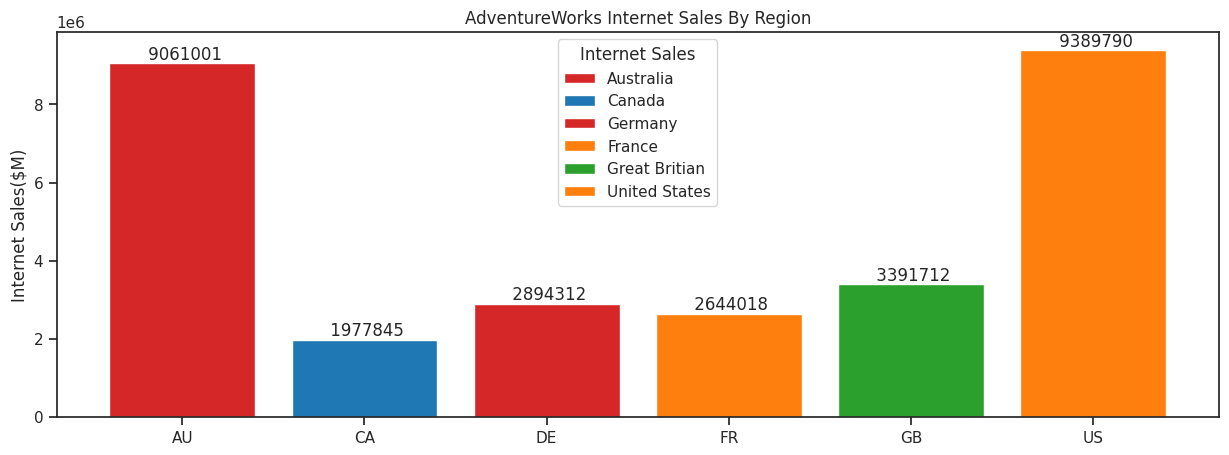

In [ ]:
# Plotting sales by region on a single axis with data labels

fig, ax = plt.subplots()
bottom = np.zeros(3)
bar_labels = ['Australia', 'Canada', 'Germany', 'France', 'Great Britian', 'United States']
bar_colors = ['tab:red', 'tab:blue', 'tab:red', 'tab:orange', 'tab:green','tab:orange']

ax.bar(results['CountryRegionCode'], results['SalesAmount'], label=bar_labels, color=bar_colors)
ax.set_ylabel('Internet Sales($M)')
ax.set_title('AdventureWorks Internet Sales By Region')
ax.legend(title='Internet Sales')
ax.set_yscale('linear')
for index, value in enumerate(results['SalesAmount']):
    plt.text(index, value, f'{value: .0f}', ha='center', va='bottom')

In [ ]:
plt.close('all') #Save the figure if you want.

In [ ]:
#Let's use a dictionary to plot sales.
data = results[['CountryRegionCode', 'SalesAmount', 'Profit']].to_dict()
data.items()

dict_items([('CountryRegionCode', {0: 'AU', 1: 'CA', 2: 'DE', 3: 'FR', 4: 'GB', 5: 'US'}), ('SalesAmount', {0: 9061000.5844, 1: 1977844.8621, 2: 2894312.3382, 3: 2644017.7143, 4: 3391712.2109, 5: 9389789.5108}), ('Profit', {0: 3685855.0763000003, 1: 829921.5012, 2: 1187370.765, 3: 1086264.7218, 4: 1390490.778, 5: 3900980.8027})])

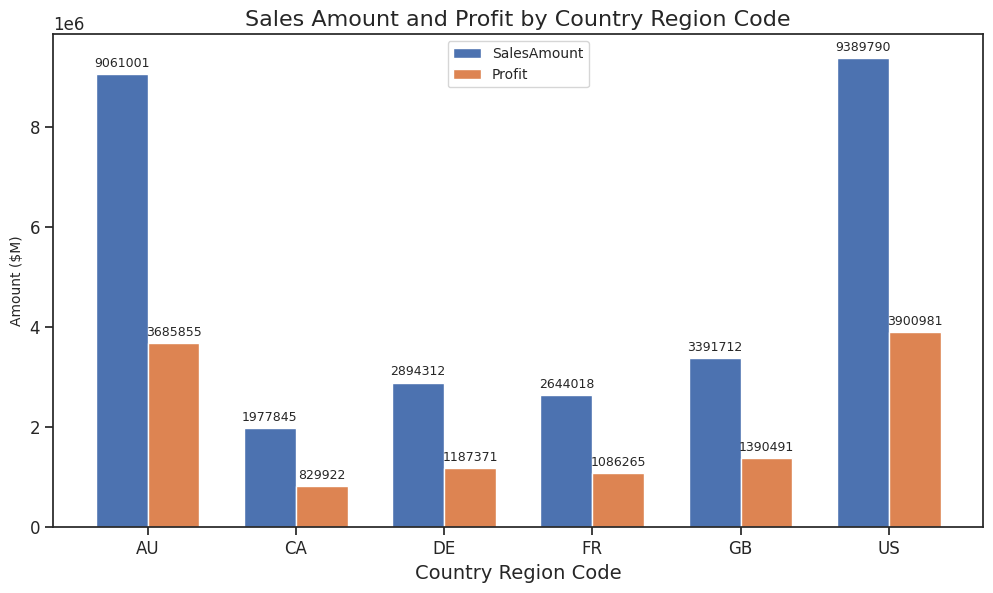

In [ ]:
#Set the font size of the visualization.  You can change this in code.  See below examples.
plt.rcParams.update({
    'font.size': 9,          # Base font size
    'axes.titlesize': 16,     # Title font size
    'axes.labelsize': 14,     # Axis label font size
    'xtick.labelsize': 12,    # X tick labels
    'ytick.labelsize': 12,    # Y tick labels
    'legend.fontsize': 12,    # Legend
})

# Extracting the data
country_codes = list(data['CountryRegionCode'].values())
sales_amount = list(data['SalesAmount'].values())
profit = list(data['Profit'].values())

# Setting the positions and width for the bars
positions = np.arange(len(country_codes))
bar_width = 0.35

# Plotting the SalesAmount and Profit side by side
plt.figure(figsize=(10, 6))
sales_bars = plt.bar(positions, sales_amount, bar_width, label='SalesAmount')
profit_bars = plt.bar(positions + bar_width, profit, bar_width, label='Profit')

# Adding data labels
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.annotate(f'{height:.0f}',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3),  # 3 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom')

add_labels(sales_bars)
add_labels(profit_bars)

# Adding xticks, title, legend
plt.xticks(positions + bar_width / 2, country_codes)
plt.title('Sales Amount and Profit by Country Region Code', fontsize=16)
plt.xlabel('Country Region Code', fontsize=14)
plt.ylabel('Amount ($M)', fontsize = 10 )
plt.legend(fontsize = 10)
ax.set_yscale('linear')
# Display the bar graph
plt.tight_layout()
plt.show()



In [ ]:
#Using the agg() method returns a dataframe
dfsales.groupby('CountryRegionCode')['SalesAmount'].agg(['min','max','mean','sum'])

,min,max,mean,sum
CountryRegionCode,,,,
AU,2,3578,679,9061001
CA,2,3578,260,1977845
DE,2,3578,515,2894312
FR,2,3578,476,2644018
GB,2,3578,491,3391712
US,2,3578,440,9389790


In [ ]:
#Using the sum method at the end of the dataframe returns a set of series not a dataframe.
#This is important if you are to use the results in other method like determining the year.
#Some methods require a dataframe, not a function.  See dtype: float64 results
regionsales = dfsales.groupby(["GeographyKey","City","CountryRegionCode"]).SalesAmount.sum
regionsales().sort_values(ascending=False)

,,,SalesAmount
GeographyKey,City,CountryRegionCode,
19,Wollongong,AU,338913
40,Warrnambool,AU,327036
32,Bendigo,AU,314569
4,Goulburn,AU,310876
298,Bellflower,US,302279
...,...,...,...
494,Charlotte,US,7
431,Carol Stream,US,7
524,Burbank,US,7


In [ ]:
countrysales = dfsales.groupby(["CountryRegionCode"]).SalesAmount.sum
countrysales().sort_values(ascending=False)

,SalesAmount
CountryRegionCode,
US,9389790
AU,9061001
GB,3391712
DE,2894312
FR,2644018
CA,1977845


##What is the average price of the product category that generates the most sales?


In [ ]:
#The Mountain-200 Black, 46 product generates the most sales and profit
# Unit Price is uses mean to determine the average selling price of a product
results = (dfsales.assign(Profit = lambda x: x['SalesAmount'] - x['TotalProductCost'])
    .groupby("EnglishProductName")
    .agg(
        {'OrderQuantity': 'sum',
         'UnitPrice': 'mean',
         'SalesAmount': 'sum',
         'TotalProductCost': 'sum',
         'Profit': 'sum',
         }
    )).reset_index().sort_values(by='Profit', ascending=False)

results.head(10) #returns the to 10 products by Profit.

,EnglishProductName,OrderQuantity,UnitPrice,SalesAmount,TotalProductCost,Profit
34,"Mountain-200 Black, 46",620,2215,1373470,746848,626622
33,"Mountain-200 Black, 42",614,2220,1363142,741382,621760
35,"Mountain-200 Silver, 38",596,2247,1339463,728598,610864
37,"Mountain-200 Silver, 46",580,2243,1301100,707610,593490
32,"Mountain-200 Black, 38",582,2225,1294866,704389,590477
36,"Mountain-200 Silver, 42",560,2245,1257435,683923,573512
58,"Road-150 Red, 48",337,3578,1205877,731726,474151
61,"Road-150 Red, 62",336,3578,1202299,729555,472744
59,"Road-150 Red, 52",302,3578,1080638,655731,424907
60,"Road-150 Red, 56",295,3578,1055590,640532,415058


##Does owning a home make a difference in sales? Explain your analysis.  Confirming the coding in the data set for owning a home: Yes = 1, No =0.

In [ ]:
#Is home ownership important?  If you wanted, you could run a statistical test to test statistical significance,
#but that was a requirement for this assignment.
homeownership = dfsales.groupby(["HouseOwnerFlag"]).SalesAmount.sum
homeownership()

,SalesAmount
HouseOwnerFlag,
0,8973327
1,20385350


In [ ]:
#Returns a series with the year component of the OrderDate as the key index
df_agg = dfsales.groupby(dfsales['OrderDate'].dt.year).SalesAmount.sum
df_agg()

,SalesAmount
OrderDate,
2010,43421
2011,7075526
2012,5842485
2013,16351550
2014,45695


In [ ]:
#EnglishEducation is the key index for the dataframe in this example.
dfsales.groupby('EnglishEducation')['SalesAmount'].agg(['min','max','mean','sum']).sort_values(by='sum', ascending=False)


,min,max,mean,sum
EnglishEducation,,,,
Bachelors,2,3578,546,9900143
Partial College,2,3578,465,7723543
Graduate Degree,2,3578,515,5460560
High School,2,3578,449,4638026
Partial High School,2,3578,348,1636405


##Generate summary statistics including min, max, and standard deviation for Yearly Income, Gender by Country Regions.  


In [ ]:
results = (dfsales.assign(Profit = lambda x: x['SalesAmount'] - x['TotalProductCost'])
    .groupby(["CountryRegionCode","Gender"])
    .agg(
        {'YearlyIncome': 'sum',
         'OrderQuantity': 'sum',
         'UnitPrice': 'mean',
         'SalesAmount': 'sum',
         'TotalProductCost': 'sum',
         'Profit': 'sum'
         }
    )).reset_index().sort_values(by='Profit', ascending=False)

results.head(10)

,CountryRegionCode,Gender,YearlyIncome,OrderQuantity,UnitPrice,SalesAmount,TotalProductCost,Profit
10,US,F,691840000,10682,444,4740582,2774062,1966520
11,US,M,697830000,10662,436,4649207,2714747,1934461
0,AU,F,448300000,6685,693,4634993,2748888,1886105
1,AU,M,435650000,6660,665,4426008,2626257,1799750
9,GB,M,195480000,3505,507,1776666,1049152,727514
8,GB,F,192220000,3401,475,1615046,952070,662976
4,DE,F,136170000,2820,546,1539713,905310,634404
7,FR,M,110540000,2777,494,1372054,811109,560945
5,DE,M,131080000,2805,483,1354599,801632,552967
6,FR,F,109480000,2781,457,1271964,746644,525320


In [ ]:
results.describe()

,YearlyIncome,OrderQuantity,UnitPrice,SalesAmount,TotalProductCost,Profit
count,12,12,12,12,12,12
mean,300555833,5033,477,2446556,1439816,1006740
std,215918969,2970,130,1616990,952797,664401
min,109480000,2777,243,966525,559720,406805
25%,134897500,2816,442,1333940,787885,546055
50%,204720000,3576,479,1577380,928690,648690
75%,438812500,6666,517,4478254,2648380,1821339
max,697830000,10682,693,4740582,2774062,1966520


In [ ]:
#Notice this returns a dataframeand the index
df_agg = dfsales.groupby(dfsales['OrderDate'].dt.year, as_index=True).agg('sum', 'mean')
df_agg

,CustomerKey,GeographyKey,NameStyle,YearlyIncome,TotalChildren,NumberChildrenAtHome,HouseOwnerFlag,NumberCarsOwned,ProductKey,OrderDateKey,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,orderyear,orderquarter,ordermonth,orderday,daynumber
OrderDate,,,,,,,,,,,,,,,,,,,,,
2010,275956,2532,0,1030000,29,14,9,31,4581,281417220,...,25572,25572,43421,3474,1086,28140,56,168,420,28728
2011,41596192,457434,0,134050000,3571,1974,1519,3046,711605,44565339730,...,4231462,4231462,7075526,566042,176888,4456376,5862,15447,35030,4506853
2012,64617789,669290,0,205250000,5288,3309,2368,4732,1241818,68350116670,...,3414478,3414478,5842485,467399,146062,6834764,9119,24212,55470,6914446
2013,994939657,12319858,0,3150400000,98685,57450,36455,80008,23588461,1062922830656,...,9586139,9586139,16351550,1308124,408791,106288413,142640,378755,825156,107492324
2014,36570522,473609,0,115940000,4208,2502,1348,3335,881159,39676026216,...,20142,20142,45695,3656,1142,3967580,1970,1970,29216,3998766


In [ ]:
#Determine yearly sales using dataframe
total_sales = df_agg['SalesAmount'].agg('sum')
print(total_sales)

29358677.2207


##Adding a forecast
As we discussed in classs, there are several ways to determine a plotline for the solution; by day, quarter, year, for example.

In [ ]:
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [ ]:

#Select the years with complete data.
yearly_sales = dfsales.assign(OrderYear = dfsales['OrderDate'].dt.year)
yearly_sales.query('"2010-12-31" < OrderDate' , inplace=True)
yearly_sales.query('OrderDate < "2013-12-29"', inplace=True)
yearly_sales = yearly_sales.groupby(['OrderYear'], as_index=False).agg({'SalesAmount':'sum'})
yearly_sales

,OrderYear,SalesAmount
0,2011,7075526
1,2012,5842485
2,2013,16346404


In [ ]:
years = np.array(yearly_sales['OrderYear'])
sales = np.array(yearly_sales['SalesAmount'])

#In NumPy, the reshape method is used to change the shape of an array without changing its data.
#This method allows you to modify the dimensions of the array, provided that the total number of
#elements in the new shape is equal to the total number of elements in the original array.
#The -1 is a placeholder that allows NumPy to automatically determine the size of that dimension based on the length of the original array.

X=years.reshape(-1,1)
y = sales.reshape(-1,1)

In [ ]:
model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [ ]:
future_dates = np.arange(2014, 2021).reshape(-1, 1)
print(future_dates)

[[2014]
 [2015]
 [2016]
 [2017]
 [2018]
 [2019]
 [2020]]


In [ ]:
forecast = model.predict(future_dates)

In [ ]:
forecast

array([[19025683.68566513],
       [23661122.93611526],
       [28296562.1865654 ],
       [32932001.43701553],
       [37567440.68746567],
       [42202879.9379158 ],
       [46838319.18836594]])

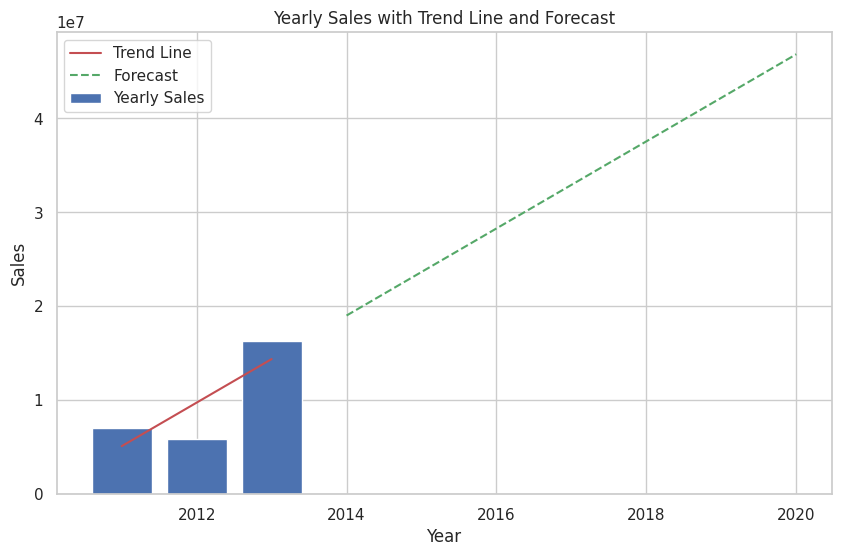

In [ ]:
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")
plt.bar(years, sales, color='b', label='Yearly Sales')
plt.plot(years, model.predict(X), color='r', label='Trend Line')
plt.plot(future_dates, forecast, linestyle='dashed', color='g', label='Forecast')
plt.title('Yearly Sales with Trend Line and Forecast')
plt.xlabel('Year')
plt.ylabel('Sales')
plt.legend()
plt.show()

In [ ]:
#Alterantively, drop outliers in 2010 and 2014 to have partial periodic sales: December 2010 and January 2014 were short months.
dfsales.query('"2010-12-31" < OrderDate' , inplace=True)
dfsales.query('OrderDate < "2013-12-29"', inplace=True)
dfsales.groupby(['orderyear','orderquarter']).agg({'SalesAmount':'sum'},as_index=True )

daily_sales = dfsales.groupby(['OrderDate','daynumber'], as_index=False).agg({'SalesAmount':'sum'})

daily_sales

,OrderDate,daynumber,SalesAmount
0,2011-01-01,2013,7157
1,2011-01-02,2014,15012
2,2011-01-03,2015,14313
3,2011-01-04,2016,7856
4,2011-01-05,2017,7856
...,...,...,...
1085,2013-12-24,2049,69534
1086,2013-12-25,2050,58081
1087,2013-12-26,2051,78907
1088,2013-12-27,2052,60960


<Figure size 1500x500 with 0 Axes>

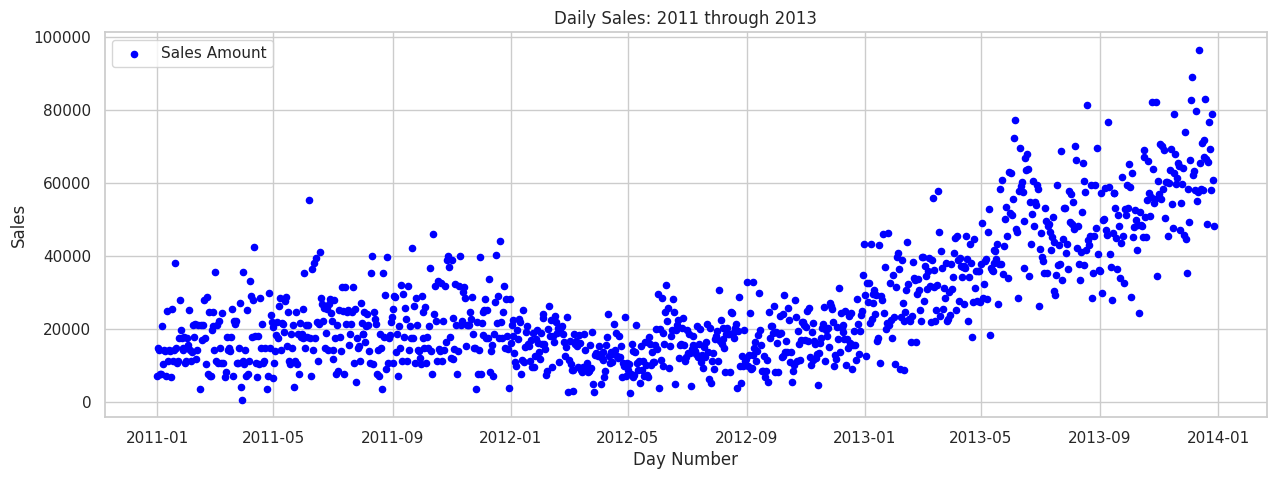

In [ ]:
fig = plt.figure()
fig.autofmt_xdate(ha='center')
fig.set_size_inches(15,5)
ax1 = fig.add_subplot
ax1 = daily_sales.plot.scatter(x='OrderDate',y='SalesAmount',label='Sales Amount', color='blue', figsize=(15,5))
ax1.set_ylabel('Sales')
ax1.set_xlabel('Day Number')
ax1.set_title('Daily Sales: 2011 through 2013')
ax1.legend()
ax1.set_yscale('linear')

In [ ]:
plt.close('all')

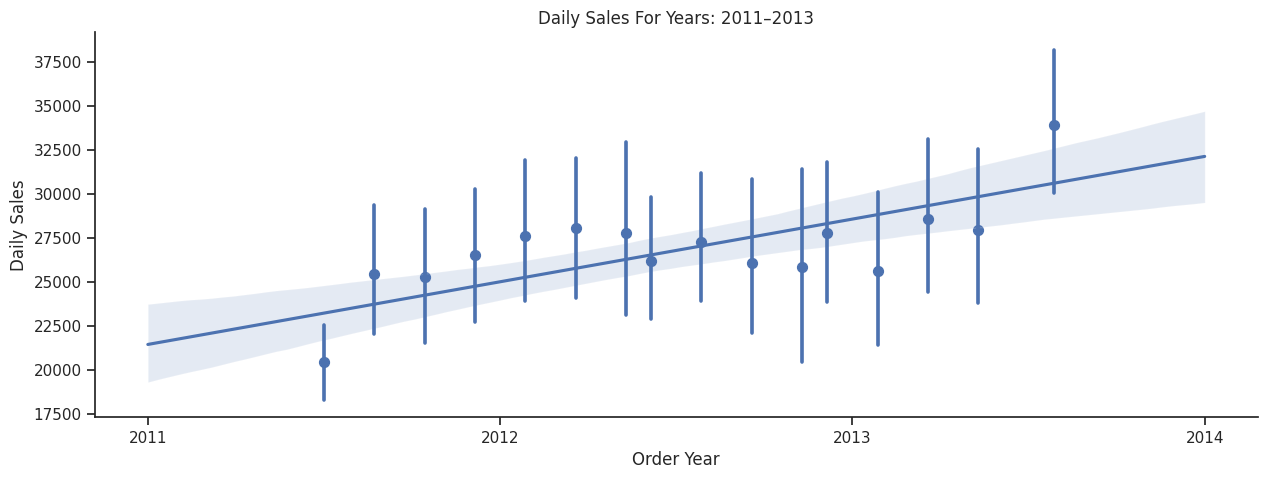

In [ ]:
#The choice of visuals is important since it impacts readability and understanding following the "Keep It Simple" principle is my choice.

sns.set_theme(style="ticks", rc={"figure.figsize": (15, 5)})

fig, ax1 = plt.subplots() #Use the regplot function to plot the simple linear regression model line with 16 bins and a 95% confidence factor.
sns.regplot(
    data=daily_sales,
    x='daynumber',
    y='SalesAmount',
    scatter=True,
    x_bins=16,
    x_estimator=np.mean,
    ci=95,
    ax=ax1
)

# Fix the ticks
# Using numpy linspace to create evenly spaced tick locations based on the range of daynumber
tick_locations = np.linspace(daily_sales['daynumber'].min(), daily_sales['daynumber'].max(), 4)
ax1.set_xticks(tick_locations)
# Setting more appropriate labels for the ticks based on the yearly data range
ax1.set_xticklabels(['2011', '2012', '2013', '2014'])


ax1.set_title("Daily Sales For Years: 2011–2013")
ax1.set_xlabel("Order Year")
ax1.set_ylabel("Daily Sales")

sns.despine()
plt.show()